# CIFAR-10 Object Classification with a CNN, for an e-puck Robot in Webots

**Applied Robotics and AI Project, Part 2**

This notebook covers every output the brief asks for:

| Brief requirement | Where |
|---|---|
| 1. Show all the layers in the model | Section 4 (`summary()`, layer table, diagram) |
| 2. Show the accuracy score | Section 5 (test accuracy, curves, confusion matrix, per-class accuracy) |
| 3. Predictions on three of my own images | Section 7 |
| 4. Prediction on an image from the Webots robot camera | Section 8 |
| Optimisation proposal (so the robot is not slowed down) | Section 9 (measured TFLite quantisation results) and Section 10 |

**How to run:** In Google Colab choose *Runtime → Change runtime type → GPU*, then *Runtime → Run all*.
The full run usually takes 10–20 minutes on a Colab T4 GPU (much longer on CPU).
Set `QUICK_RUN = True` in Section 1 to check that everything runs in about 2 minutes (accuracy will be low).

## 1. Setup
A fixed random seed makes the data split, weight initialisation and shuffling repeatable. Results are *approximately* reproducible: GPU kernels are not bit-for-bit deterministic, so accuracy can vary by a few tenths of a percent between runs.

In [1]:
import os, sys, time, pathlib
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models

QUICK_RUN = os.environ.get("QUICK_RUN") == "1"   # True = smoke test only (few epochs, small data)
SEED = 42
keras.utils.set_random_seed(SEED)

IN_COLAB = "google.colab" in sys.modules
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "none (CPU only - training will be slower)")
print("Colab:", IN_COLAB, "| QUICK_RUN:", QUICK_RUN)

CLASS_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']
OUT_DIR = pathlib.Path("outputs"); OUT_DIR.mkdir(exist_ok=True)

TensorFlow 2.21.0 | Keras 3.15.1
GPU: none (CPU only - training will be slower)
Colab: False | QUICK_RUN: False


## 2. Load and prepare CIFAR-10
CIFAR-10 has 60,000 colour images (32×32×3) in 10 classes: 50,000 for training and 10,000 for testing (Krizhevsky, 2009).

**Fix compared with the lecture notebook:** the lecture version passed the *test* set as `validation_data`.
Picking the best epoch or optimiser by looking at test accuracy leaks test information into training decisions, so the final test score is then optimistic.
Here 5,000 training images are held out as a separate **validation set**, and every decision (optimiser, epochs, quantisation variant) is made on validation accuracy. The test set only *reports* results and is never used to choose anything.

In [2]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.cifar10.load_data()
y_train_full, y_test = y_train_full.ravel(), y_test.ravel()   # (N,1) -> (N,)

# Normalise pixel values from 0..255 to 0..1 (helps gradient descent converge)
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Random split: 5,000 shuffled training images -> validation, the rest -> training
idx = np.random.default_rng(SEED).permutation(len(x_train_full))
val_idx, train_idx = idx[:5000], idx[5000:]
x_train, y_train = x_train_full[train_idx], y_train_full[train_idx]
x_val, y_val = x_train_full[val_idx], y_train_full[val_idx]

if QUICK_RUN:
    x_train, y_train = x_train[:5000], y_train[:5000]

print(f"train {x_train.shape}  val {x_val.shape}  test {x_test.shape}")
print("images per class in train:", np.bincount(y_train))

train (45000, 32, 32, 3)  val (5000, 32, 32, 3)  test (10000, 32, 32, 3)
images per class in train: [4527 4458 4465 4518 4477 4527 4498 4531 4482 4517]


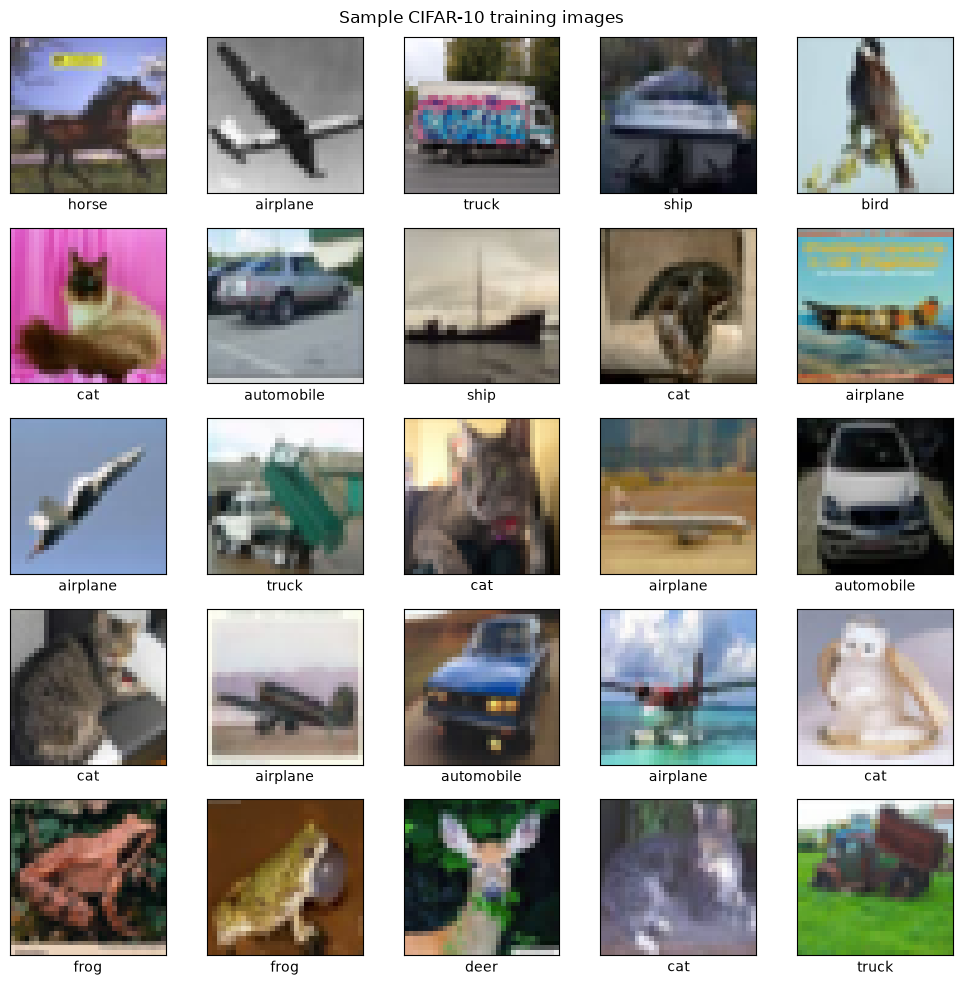

In [3]:
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([]); plt.yticks([]); plt.grid(False)
    plt.imshow(x_train[i])
    plt.xlabel(CLASS_NAMES[y_train[i]])
plt.suptitle("Sample CIFAR-10 training images")
plt.tight_layout(); plt.show()

## 3. Baseline: the lecture CNN (SGD vs Adam)
The lecture architecture is trained twice as a benchmark: once with SGD and once with Adam.

**Fix compared with the lecture notebook:** the lecture re-compiled the *same* model with Adam after training it with SGD.
The Adam run therefore started from SGD's already-trained weights, so it was really 20 epochs and not a fair comparison.
Here each optimiser gets a **freshly built model**.

The last layer has no softmax. It outputs raw scores (logits), and `from_logits=True` tells the loss to apply softmax internally, which is more numerically stable.

In [4]:
def build_baseline():
    # Exactly the lecture architecture (Conv32-Pool-Conv64-Pool-Conv64-Dense64-Dense10)
    return models.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dense(10),
    ], name="baseline_cnn")

LOSS = keras.losses.SparseCategoricalCrossentropy(from_logits=True)
BASE_EPOCHS = 1 if QUICK_RUN else 10
results = {}      # name -> dict(test_acc, params, history)

for opt_name in ["sgd", "adam"]:
    keras.utils.set_random_seed(SEED)            # same initial weights for both
    m = build_baseline()
    m.compile(optimizer=opt_name, loss=LOSS, metrics=["accuracy"])
    t0 = time.time()
    h = m.fit(x_train, y_train, epochs=BASE_EPOCHS, batch_size=32,
              validation_data=(x_val, y_val), verbose=2)
    _, val_acc = m.evaluate(x_val, y_val, verbose=0)
    _, acc = m.evaluate(x_test, y_test, verbose=0)
    results[f"Baseline + {opt_name.upper()}"] = dict(val_acc=val_acc, test_acc=acc, params=m.count_params(),
                                                     history=h.history, train_s=time.time() - t0)
    print(f"==> Baseline + {opt_name.upper()}: validation {val_acc:.4f} | test {acc:.4f}\n")

Epoch 1/10


1407/1407 - 7s - 5ms/step - accuracy: 0.2225 - loss: 2.1116 - val_accuracy: 0.2888 - val_loss: 1.9121


Epoch 2/10


1407/1407 - 8s - 6ms/step - accuracy: 0.3874 - loss: 1.7091 - val_accuracy: 0.3740 - val_loss: 1.7058


Epoch 3/10


1407/1407 - 8s - 5ms/step - accuracy: 0.4607 - loss: 1.4984 - val_accuracy: 0.3870 - val_loss: 1.7132


... (31 outputs left out)

1407/1407 - 10s - 7ms/step - accuracy: 0.7769 - loss: 0.6467 - val_accuracy: 0.6746 - val_loss: 1.0196


Epoch 10/10


1407/1407 - 10s - 7ms/step - accuracy: 0.7888 - loss: 0.6097 - val_accuracy: 0.6712 - val_loss: 1.0513


==> Baseline + ADAM: validation 0.6712 | test 0.6690



## 4. Improved CNN: output 1, all the layers
In the lecture's run the baseline overfits: training accuracy keeps rising while validation accuracy flattens at about 70% (lecture notes, *Overfitting* slide). Check the same pattern in the curves in Section 5.
The improved model fixes this with standard, well-justified techniques:

| Technique | Why |
|---|---|
| **Data augmentation** (random flip, shift, zoom) | Shows the network new variations of each image every epoch, which reduces overfitting. These layers are only active during training. |
| **Two 3×3 convolutions per block** (VGG style, Simonyan & Zisserman, 2015) | Gives a larger receptive field and more non-linearity than one big filter, with fewer parameters. |
| **Batch Normalisation** (Ioffe & Szegedy, 2015) | Stabilises and speeds up training. |
| **Dropout** (Srivastava et al., 2014) | Randomly switches off units during training, so the network cannot rely on single features. |
| **Global Average Pooling** instead of Flatten (Lin et al., 2014) | Far fewer weights in the classifier head, so the model is smaller and faster on the robot. |
| **Early stopping + learning-rate reduction** | Stops when validation loss stops improving and keeps the best weights. |

In [5]:
def conv_block(x, filters, dropout):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D(2)(x)
    return layers.Dropout(dropout)(x)

def build_improved(augment=True):
    inputs = layers.Input(shape=(32, 32, 3), name="image")
    x = inputs
    if augment:                                          # augmentation (active in training only)
        x = layers.RandomFlip("horizontal")(x)
        x = layers.RandomTranslation(0.1, 0.1)(x)
        x = layers.RandomZoom(0.1)(x)
    x = conv_block(x, 32, 0.2)     # 32x32 -> 16x16
    x = conv_block(x, 64, 0.3)     # 16x16 -> 8x8
    x = conv_block(x, 128, 0.4)    # 8x8   -> 4x4
    x = layers.GlobalAveragePooling2D()(x)               # 4x4x128 -> 128
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(10, name="logits")(x)          # raw scores, softmax applied in the loss
    return keras.Model(inputs, outputs, name="improved_cnn")

keras.utils.set_random_seed(SEED)
model = build_improved()
model.summary()

Model: "improved_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 306,154 (1.17 MB)

 Trainable params: 305,258 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

In [6]:
# Layer-by-layer table: every layer, its output shape and number of parameters
print(f"{'#':>2}  {'Layer (type)':<36}{'Output shape':<22}{'Params':>10}")
print("-" * 72)
for i, layer in enumerate(model.layers):
    shape = tuple(layer.output.shape)
    print(f"{i:>2}  {layer.name + ' (' + layer.__class__.__name__ + ')':<36}{str(shape):<22}{layer.count_params():>10,}")
print("-" * 72)
print(f"Total parameters: {model.count_params():,}")

 #  Layer (type)                        Output shape              Params
------------------------------------------------------------------------
 0  image (InputLayer)                  (None, 32, 32, 3)              0
 1  random_flip (RandomFlip)            (None, 32, 32, 3)              0
 2  random_translation (RandomTranslation)(None, 32, 32, 3)              0
 3  random_zoom (RandomZoom)            (None, 32, 32, 3)              0
 4  conv2d_6 (Conv2D)                   (None, 32, 32, 32)           864
 5  batch_normalization (BatchNormalization)(None, 32, 32, 32)           128
 6  activation (Activation)             (None, 32, 32, 32)             0
 7  conv2d_7 (Conv2D)                   (None, 32, 32, 32)         9,216
 8  batch_normalization_1 (BatchNormalization)(None, 32, 32, 32)           128
 9  activation_1 (Activation)           (None, 32, 32, 32)             0
10  max_pooling2d_4 (MaxPooling2D)      (None, 16, 16, 32)             0
11  dropout (Dropout)                  

In [7]:
# Architecture diagram for the report (needs pydot + graphviz; both are preinstalled in Colab)
try:
    keras.utils.plot_model(model, to_file=str(OUT_DIR / "model_architecture.png"),
                           show_shapes=True, show_layer_names=True, dpi=72)
    from IPython.display import Image, display
    display(Image(str(OUT_DIR / "model_architecture.png")))
except (ImportError, OSError) as e:
    print("Diagram skipped (install pydot and graphviz to enable):", e)

Diagram skipped (install pydot and graphviz to enable): You must install pydot (`pip install pydot`) for `plot_model` to work.


### Training the improved model
* **Optimiser:** Adam (Kingma & Ba, 2015) at learning rate 1e-3. In the lecture results and the baseline comparison above (compare the validation accuracies), Adam learns faster than plain SGD in 10 epochs.
* **Early stopping** watches validation loss with patience 10 and restores the best weights, so we keep the best epoch and not the last one.
* **ReduceLROnPlateau** halves the learning rate when validation loss stalls, for finer convergence.

In [8]:
EPOCHS = 2 if QUICK_RUN else 80
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=LOSS, metrics=["accuracy"])
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5, verbose=1),
]
t0 = time.time()
history = model.fit(x_train, y_train, epochs=EPOCHS, batch_size=64,
                    validation_data=(x_val, y_val), callbacks=callbacks, verbose=2)
train_time = time.time() - t0
print(f"Training took {train_time/60:.1f} min for {len(history.history['loss'])} epochs")

Epoch 1/80


704/704 - 68s - 96ms/step - accuracy: 0.3878 - loss: 1.6663 - val_accuracy: 0.2874 - val_loss: 2.5967 - learning_rate: 0.0010


Epoch 2/80


704/704 - 65s - 92ms/step - accuracy: 0.5324 - loss: 1.3097 - val_accuracy: 0.4074 - val_loss: 1.9334 - learning_rate: 0.0010


Epoch 3/80


704/704 - 66s - 93ms/step - accuracy: 0.5884 - loss: 1.1661 - val_accuracy: 0.5174 - val_loss: 1.7132 - learning_rate: 0.0010


... (159 outputs left out)

Epoch 80/80


704/704 - 68s - 96ms/step - accuracy: 0.8763 - loss: 0.3629 - val_accuracy: 0.8718 - val_loss: 0.4020 - learning_rate: 1.0000e-05


Restoring model weights from the end of the best epoch: 80.


Training took 88.7 min for 80 epochs


## 5. Output 2: accuracy score

In [9]:
_, val_acc = model.evaluate(x_val, y_val, verbose=0)
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
results["Improved CNN + Adam"] = dict(val_acc=val_acc, test_acc=test_acc, params=model.count_params(),
                                     history=history.history, train_s=train_time)
print(f"TEST ACCURACY (10,000 unseen images): {test_acc:.4f}  ({test_acc:.2%})")
se = np.sqrt(test_acc * (1 - test_acc) / len(y_test))
print(f"Test loss: {test_loss:.4f}   95% confidence interval: ±{1.96*se:.2%} (binomial, n=10,000)\n")
print(f"{'Model':<24}{'Val accuracy':>13}{'Test accuracy':>14}{'Parameters':>12}{'Epochs':>8}")
for name, r in results.items():
    print(f"{name:<24}{r['val_acc']:>13.2%}{r['test_acc']:>14.2%}{r['params']:>12,}{len(r['history']['loss']):>8}")
print(f"{'Random guessing':<24}{'':>13}{0.10:>14.2%}")

TEST ACCURACY (10,000 unseen images): 0.8647  (86.47%)
Test loss: 0.4365   95% confidence interval: ±0.67% (binomial, n=10,000)

Model                    Val accuracy Test accuracy  Parameters  Epochs
Baseline + SGD                 59.62%        60.61%     122,570      10
Baseline + ADAM                67.12%        66.90%     122,570      10
Improved CNN + Adam            87.18%        86.47%     306,154      80
Random guessing                              10.00%


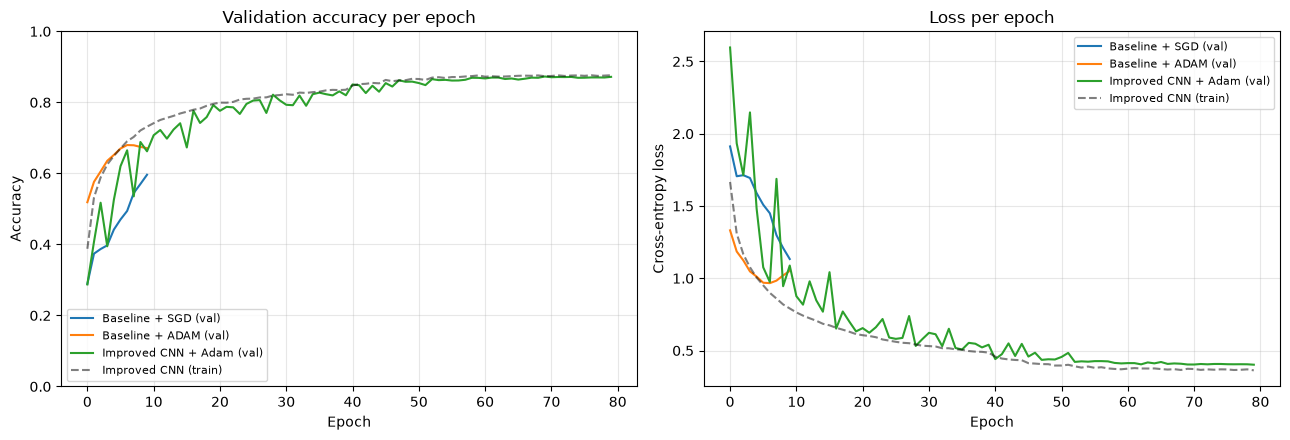

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, r in results.items():
    h = r["history"]
    axes[0].plot(h["val_accuracy"], label=f"{name} (val)")
    axes[1].plot(h["val_loss"], label=f"{name} (val)")
axes[0].plot(history.history["accuracy"], "k--", alpha=.5, label="Improved CNN (train)")
axes[1].plot(history.history["loss"], "k--", alpha=.5, label="Improved CNN (train)")
axes[0].set(title="Validation accuracy per epoch", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1))
axes[1].set(title="Loss per epoch", xlabel="Epoch", ylabel="Cross-entropy loss")
for ax in axes: ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / "training_curves.png", dpi=150); plt.show()

### Error analysis: which classes get confused?
The overall accuracy hides where the model fails. The confusion matrix shows which true class (row) is predicted as which class (column).

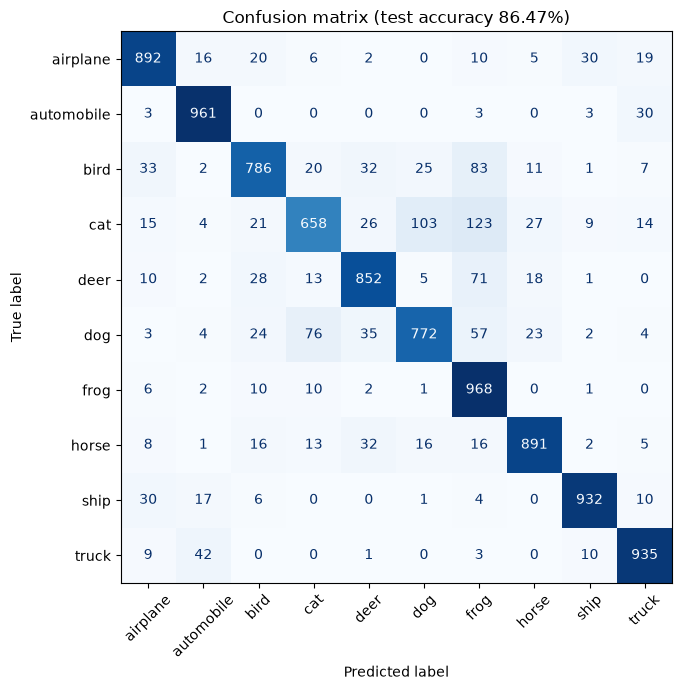

              precision    recall  f1-score   support

    airplane      0.884     0.892     0.888      1000
  automobile      0.914     0.961     0.937      1000
        bird      0.863     0.786     0.823      1000
         cat      0.827     0.658     0.733      1000
        deer      0.868     0.852     0.860      1000
         dog      0.836     0.772     0.803      1000
        frog      0.723     0.968     0.828      1000
       horse      0.914     0.891     0.902      1000
        ship      0.940     0.932     0.936      1000
       truck      0.913     0.935     0.924      1000

    accuracy                          0.865     10000
   macro avg      0.868     0.865     0.863     10000
weighted avg      0.868     0.865     0.863     10000

Most common confusions:
         cat -> frog        123 images
         cat -> dog         103 images
        bird -> frog         83 images
         dog -> cat          76 images
        deer -> frog         71 images


In [11]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

test_logits = model.predict(x_test, batch_size=256, verbose=0)
y_pred = test_logits.argmax(axis=1)
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title(f"Confusion matrix (test accuracy {test_acc:.2%})")
plt.tight_layout(); plt.savefig(OUT_DIR / "confusion_matrix.png", dpi=150); plt.show()

print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3))

off = cm.copy(); np.fill_diagonal(off, 0)
print("Most common confusions:")
for k in np.argsort(off.ravel())[::-1][:5]:
    t, p = divmod(k, 10)
    print(f"  {CLASS_NAMES[t]:>10} -> {CLASS_NAMES[p]:<10} {off[t, p]:>4} images")

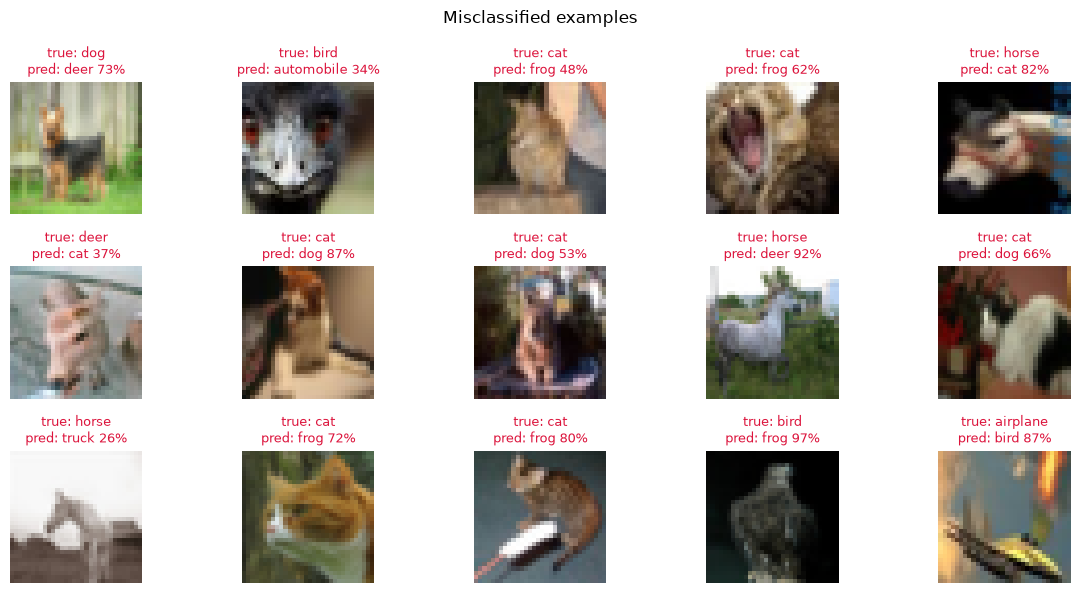

In [12]:
# Some misclassified test images with the model's confidence
probs = tf.nn.softmax(test_logits).numpy()
wrong = np.where(y_pred != y_test)[0][:15]
plt.figure(figsize=(12, 6))
for i, k in enumerate(wrong):
    plt.subplot(3, 5, i + 1); plt.imshow(x_test[k]); plt.axis("off")
    plt.title(f"true: {CLASS_NAMES[y_test[k]]}\npred: {CLASS_NAMES[y_pred[k]]} {probs[k].max():.0%}",
              fontsize=9, color="crimson")
plt.suptitle("Misclassified examples"); plt.tight_layout(); plt.show()

## 6. Save the model
The notebook saves the native Keras format (`.keras`).

**Fix compared with the lecture notebook:** the lecture saved `final_model.keras` but then loaded `final_model.h5`, which crashes with *file not found*. The same path is used for both here.

In [13]:
MODEL_PATH = OUT_DIR / "cifar10_cnn.keras"
model.save(MODEL_PATH)
reloaded = keras.models.load_model(MODEL_PATH)
assert np.allclose(reloaded.predict(x_test[:8], verbose=0), model.predict(x_test[:8], verbose=0), atol=1e-4)
print(f"Saved and verified: {MODEL_PATH} ({MODEL_PATH.stat().st_size/1e6:.2f} MB)")

Saved and verified: outputs/cifar10_cnn.keras (3.80 MB)


## 7. Output 3: predictions on three of my own images
Put three or more of your own photos (`.jpg`/`.png`) of CIFAR-10 objects (for example a car, a cat and a plane) in a folder called `my_images/`.
In Colab, the cell below asks you to upload them if the folder is empty.

**Preprocessing that matches training and the robot:** the image is centre-cropped to a square *before* resizing to 32×32 with OpenCV `INTER_AREA`, which is exactly the function the robot's `classifier.py` uses.
Resizing a 4:3 photo straight to 32×32 (as the lecture's `load_img(target_size=(32,32))` does) squashes the object, and the CNN never saw squashed objects during training.
The image is then converted to RGB and scaled to 0–1, exactly like the training data.

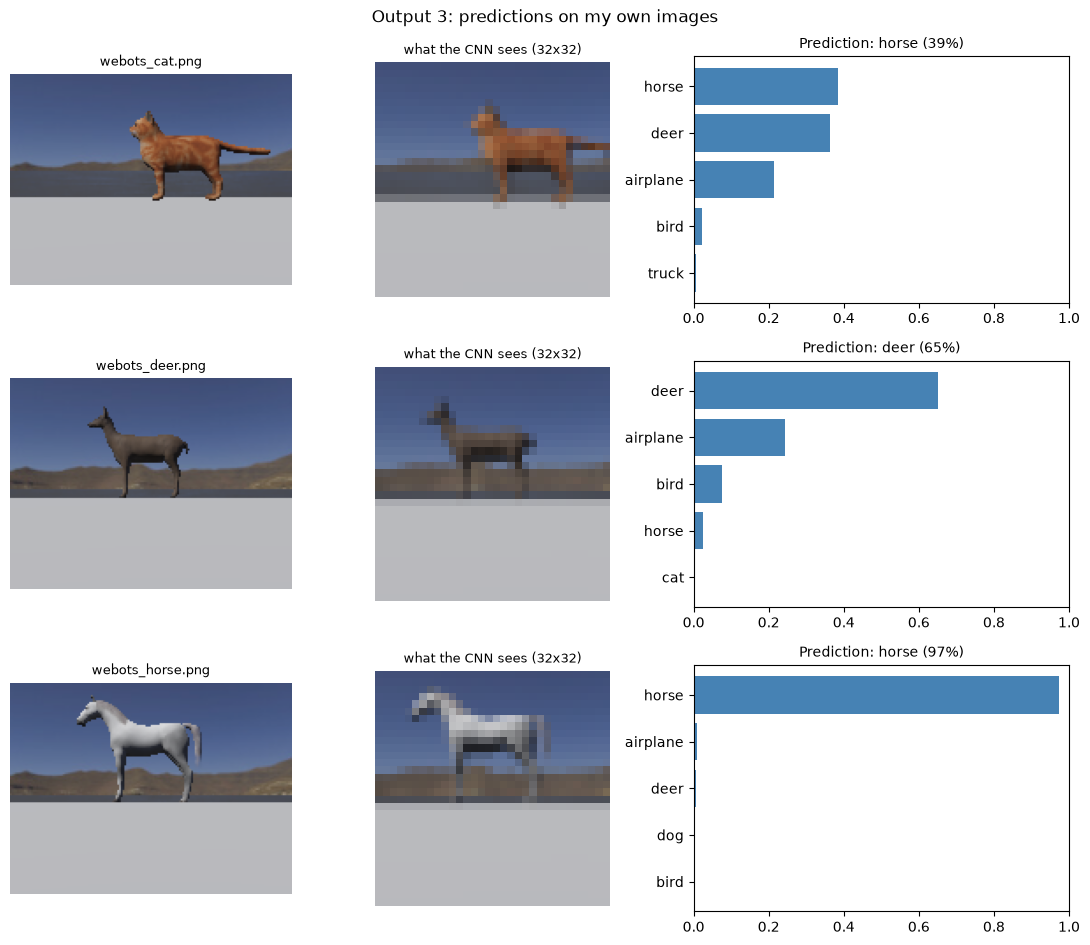

webots_cat.png                 -> horse       confidence 38.6%
webots_deer.png                -> deer        confidence 65.0%
webots_horse.png               -> horse       confidence 97.4%


In [14]:
import cv2 as cv
from PIL import Image as PILImage

def load_for_cnn(path):
    # Any image -> (32,32,3) float32 RGB in [0,1]. Same steps as the robot's classifier.preprocess:
    # centre square crop, OpenCV INTER_AREA resize (area averaging, right for shrinking), /255.
    rgb = np.asarray(PILImage.open(path).convert("RGB"))
    h, w = rgb.shape[:2]
    s = min(w, h)
    crop = rgb[(h - s) // 2:(h - s) // 2 + s, (w - s) // 2:(w - s) // 2 + s]
    return cv.resize(crop, (32, 32), interpolation=cv.INTER_AREA).astype("float32") / 255.0

def predict_and_show(paths, title):
    if not paths:
        print("No images found."); return []
    out = []
    fig, axes = plt.subplots(len(paths), 3, figsize=(11, 3.2 * len(paths)), squeeze=False,
                             gridspec_kw={"width_ratios": [1.2, 1, 1.6]})
    for row, path in enumerate(paths):
        x = load_for_cnn(path)
        p = tf.nn.softmax(model.predict(x[None], verbose=0)[0]).numpy()
        top = np.argsort(p)[::-1]
        out.append((pathlib.Path(path).name, CLASS_NAMES[top[0]], float(p[top[0]])))
        axes[row, 0].imshow(PILImage.open(path).convert("RGB")); axes[row, 0].set_title(pathlib.Path(path).name, fontsize=9)
        axes[row, 1].imshow(x); axes[row, 1].set_title("what the CNN sees (32x32)", fontsize=9)
        axes[row, 2].barh([CLASS_NAMES[i] for i in top[:5]][::-1], p[top[:5]][::-1], color="steelblue")
        axes[row, 2].set_xlim(0, 1); axes[row, 2].set_title(f"Prediction: {CLASS_NAMES[top[0]]} ({p[top[0]]:.0%})", fontsize=10)
        for ax in axes[row, :2]: ax.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()
    for name, label, conf in out:
        print(f"{name:<30} -> {label:<11} confidence {conf:.1%}")
    return out

def images_in(folder):
    return sorted(p for p in pathlib.Path(folder).glob("*") if p.suffix.lower() in {".png", ".jpg", ".jpeg", ".bmp", ".webp"})

MY_DIR = pathlib.Path("my_images"); MY_DIR.mkdir(exist_ok=True)
if not images_in(MY_DIR) and IN_COLAB:
    from google.colab import files
    print("Upload 3 of your own photos:")
    for name, data in files.upload().items():
        (MY_DIR / name).write_bytes(data)
my_results = predict_and_show(images_in(MY_DIR), "Output 3: predictions on my own images")
if len(my_results) < 3:
    print(f"\nNOTE: the brief asks for 3 own images; {len(my_results)} found in {MY_DIR}/")

## 8. Output 4: prediction on an image from the Webots robot camera
The Webots controller (`colour_detector.py`) saves every camera snapshot to `controllers/colour_detector/images/`:
* `startup_001.png`: the first frame. In `cnn_camera_test.wbt` the e-puck starts facing a **dog**, which is a CIFAR-10 class.
* `*_block_*_cnn_input.png`: the 32×32 crop the robot itself would send to the CNN when it reaches a coloured block.

Copy those PNGs into `webots_images/` (or upload them when asked) and run the cell. The `_cnn_input.png` files are already the exact 32×32 crop the robot made, so the notebook classifies precisely what the robot would.

**What to expect:** a red, green or blue box is **not** one of the 10 CIFAR-10 classes, so the CNN *must* answer with one of the classes it knows, and usually picks something box-like such as `truck`, `automobile` or `ship`.
This is a key finding for the report. A classifier trained on CIFAR-10 cannot recognise objects outside its classes, and it gives no "unknown" answer. The coloured blocks are therefore recognised by the HSV colour detector, and the CNN is tested on the dog, which is in its training classes.

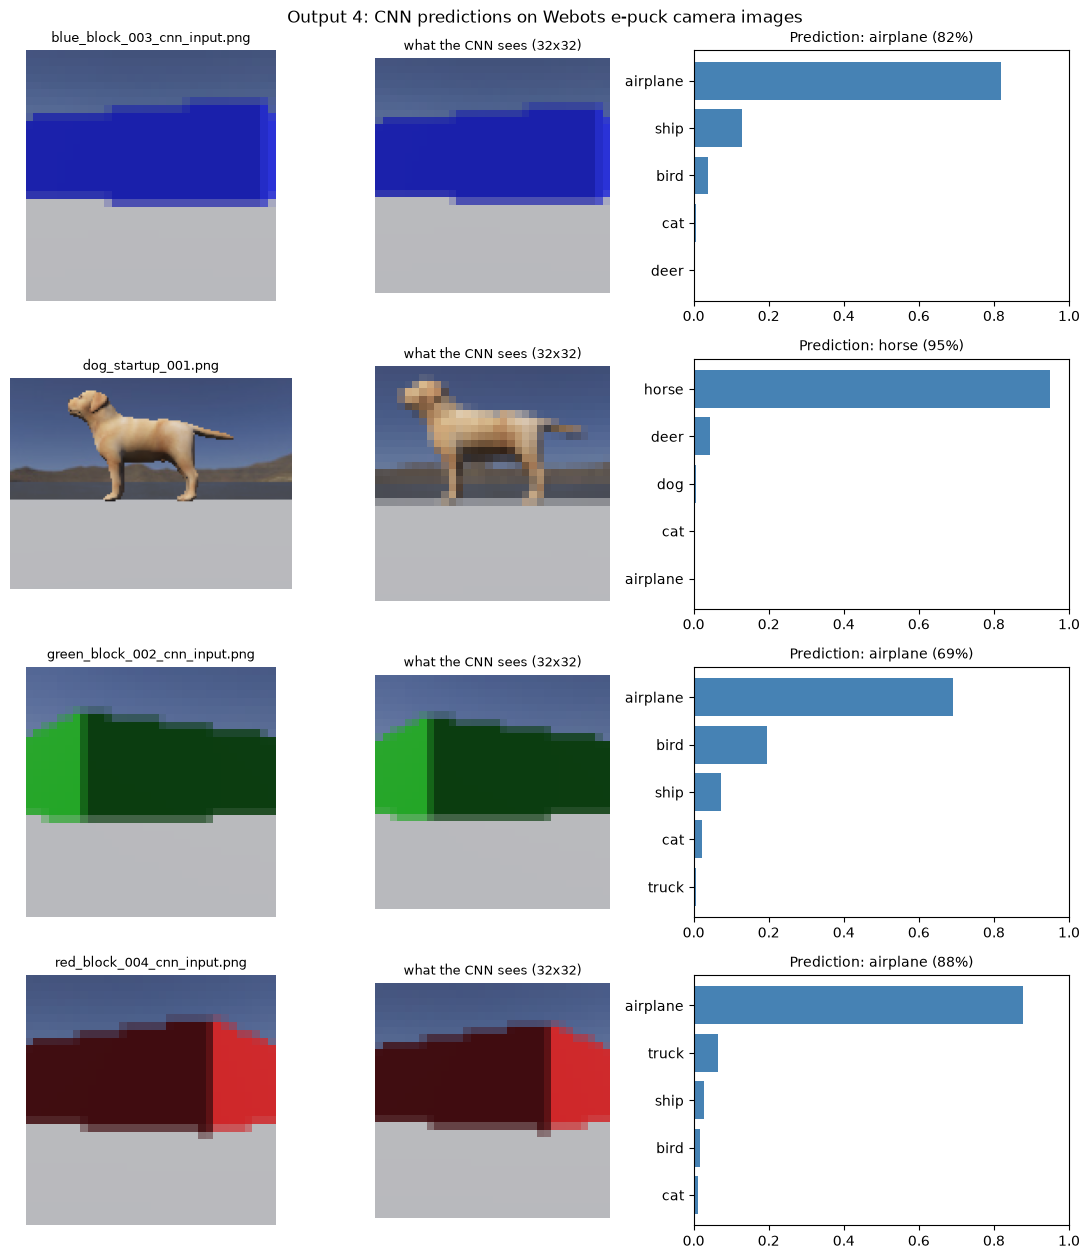

blue_block_003_cnn_input.png   -> airplane    confidence 81.9%
dog_startup_001.png            -> horse       confidence 94.9%
green_block_002_cnn_input.png  -> airplane    confidence 69.0%
red_block_004_cnn_input.png    -> airplane    confidence 87.6%


In [15]:
WB_DIR = pathlib.Path("webots_images"); WB_DIR.mkdir(exist_ok=True)
if not images_in(WB_DIR) and IN_COLAB:
    from google.colab import files
    print("Upload images saved by the Webots robot camera (e.g. startup_001.png):")
    for name, data in files.upload().items():
        (WB_DIR / name).write_bytes(data)
webots_paths = [p for p in images_in(WB_DIR) if "annotated" not in p.name]
webots_results = predict_and_show(webots_paths, "Output 4: CNN predictions on Webots e-puck camera images")

## 9. Optimisation: making the CNN fast enough for the robot
The robot's control loop runs every **32 ms**. Any inference that takes longer would freeze the motors and obstacle avoidance.
Here we measure what **post-training quantisation** with TensorFlow Lite (Jacob et al., 2018) does to size, speed and accuracy:

| Variant | What it does |
|---|---|
| Keras float32 | The trained model as-is (reference) |
| TFLite float32 | Same weights, converted to the lightweight TFLite runtime |
| TFLite float16 | Weights stored as 16-bit floats, so the model is about 2× smaller |
| TFLite dynamic-range int8 | Weights stored as 8-bit integers, about 4× smaller |
| TFLite full int8 | Weights **and** activations in int8, calibrated on 500 training images. This suits microcontrollers and edge TPUs. |

Latency is measured with **batch size 1 on the CPU**, which matches how the robot classifies one camera frame at a time.

In [16]:
# Export a deployment model without the augmentation layers (they do nothing at inference
# time, but some TFLite converters/ops do not support them).
deploy_model = build_improved(augment=False)
deploy_model.set_weights(model.get_weights())   # augmentation layers have no weights
AUG = (layers.RandomFlip, layers.RandomTranslation, layers.RandomZoom)
assert not any(isinstance(l, AUG) for l in deploy_model.layers)
assert np.allclose(deploy_model.predict(x_val[:256], verbose=0), model.predict(x_val[:256], verbose=0), atol=1e-4)
print("Deployment model matches the trained model on 256 validation images.")

def convert(mode):
    conv = tf.lite.TFLiteConverter.from_keras_model(deploy_model)
    if mode in ("float16", "dynamic", "int8"):
        conv.optimizations = [tf.lite.Optimize.DEFAULT]
    if mode == "float16":
        conv.target_spec.supported_types = [tf.float16]
    if mode == "int8":
        rep = x_train[np.random.default_rng(SEED).choice(len(x_train), 500, replace=False)]
        conv.representative_dataset = lambda: ([s[None]] for s in rep)
        conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
        conv.inference_input_type = tf.int8
        conv.inference_output_type = tf.int8
    return conv.convert()

TFLITE_FILES = {"TFLite float32": "cifar10_cnn.tflite", "TFLite float16": "cifar10_cnn_fp16.tflite",
                "TFLite dynamic int8": "cifar10_cnn_dynamic.tflite", "TFLite full int8": "cifar10_cnn_int8.tflite"}
for (name, fname), mode in zip(TFLITE_FILES.items(), ["float32", "float16", "dynamic", "int8"]):
    (OUT_DIR / fname).write_bytes(convert(mode))
    print(f"{name:<22} -> {fname:<28} {(OUT_DIR / fname).stat().st_size/1e3:8.1f} kB")

Deployment model matches the trained model on 256 validation images.


INFO:tensorflow:Assets written to: /var/folders/lw/r882xcn95f3dhmf7snjkn__00000gn/T/tmpc_r3xyqf/assets


INFO:tensorflow:Assets written to: /var/folders/lw/r882xcn95f3dhmf7snjkn__00000gn/T/tmpc_r3xyqf/assets


Saved artifact at '/var/folders/lw/r882xcn95f3dhmf7snjkn__00000gn/T/tmpc_r3xyqf'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 32, 32, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  5097503056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5097497104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5097504016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5097504592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5097504208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5097503440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5104485584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5104485776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5097503632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5097501136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5104486160: TensorSpec(shape

W0000 00:00:1794434612.619285 4437912 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1794434612.619296 4437912 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1794434612.619819 4437912 reader.cc:83] Reading SavedModel from: /var/folders/lw/r882xcn95f3dhmf7snjkn__00000gn/T/tmpc_r3xyqf
I0000 00:00:1794434612.620455 4437912 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1794434612.620458 4437912 reader.cc:147] Reading SavedModel debug info (if present) from: /var/folders/lw/r882xcn95f3dhmf7snjkn__00000gn/T/tmpc_r3xyqf
I0000 00:00:1794434612.625676 4437912 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1794434612.626655 4437912 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1794434612.661407 4437912 loader.cc:220] Running initialization op on SavedModel bundle at path: /var/folders/lw/r882xcn95f3dhmf7snjkn__00000gn/T/tmpc_r3xyqf
I0000 00:00:1794434612.670628 4437912 lo

TFLite float32         -> cifar10_cnn.tflite             1226.0 kB


... (13 outputs left out)

/private/tmp/claude-501/-Users-krishnamahajan-Library-Application-Support-Claude-scratch-workspaces-7a395be2-a6ae-420e-83f5-80271cad5f7c-dee63cf5-31ea-4364-82fe-af1e63d02abf-scratch-2026-11-11-8f8053/5e048983-eb6f-413f-a49a-79271b128064/scratchpad/venv/lib/python3.12/site-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1794434614.495008 4437912 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1794434614.495014 4437912 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.


I0000 00:00:1794434614.495085 4437912 reader.cc:83] Reading SavedModel from: /var/folders/lw/r882xcn95f3dhmf7snjkn__00000gn/T/tmpz4un7mg1
I0000 00:00:1794434614.495675 4437912 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1794434614.495677 4437912 reader.cc:147] Reading SavedModel debug info (if present) from: /var/folders/lw/r882xcn95f3dhmf7snjkn__00000gn/T/tmpz4un7mg1
I0000 00:00:1794434614.501348 4437912 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1794434614.532950 4437912 loader.cc:220] Running initialization op on SavedModel bundle at path: /var/folders/lw/r882xcn95f3dhmf7snjkn__00000gn/T/tmpz4un7mg1
I0000 00:00:1794434614.542015 4437912 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 46931 microseconds.
fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8


W0000 00:00:1794434615.756923 4437912 flatbuffer_export.cc:3851] Skipping runtime version metadata in the model. This will be generated by the exporter.


TFLite full int8       -> cifar10_cnn_int8.tflite         328.2 kB


In [17]:
class TFLiteModel:
    # Run a .tflite file; handles quantised int8 input/output automatically
    def __init__(self, path):
        self.it = tf.lite.Interpreter(model_path=str(path), num_threads=1)
        self.it.allocate_tensors()
        self.inp, self.out = self.it.get_input_details()[0], self.it.get_output_details()[0]
    def __call__(self, x1):                       # x1: (1,32,32,3) float32
        if self.inp["dtype"] != np.float32:
            s, z = self.inp["quantization"]
            info = np.iinfo(self.inp["dtype"])
            x1 = np.clip(np.round(x1 / s + z), info.min, info.max).astype(self.inp["dtype"])
        self.it.set_tensor(self.inp["index"], x1); self.it.invoke()
        y = self.it.get_tensor(self.out["index"])
        if self.out["dtype"] != np.float32:
            s, z = self.out["quantization"]; y = (y.astype(np.float32) - z) * s
        return y

N_ACC = 1000 if QUICK_RUN else len(x_test)    # accuracy on the full test set
N_LAT = 300                                    # timed single-image inferences

def benchmark(predict_one):
    for i in range(20): predict_one(x_test[i:i+1])                     # warm-up
    times = []
    for i in range(N_LAT):
        t0 = time.perf_counter(); predict_one(x_test[i:i+1]); times.append(time.perf_counter() - t0)
    preds = np.array([predict_one(x_test[i:i+1])[0].argmax() for i in range(N_ACC)])
    return np.median(times) * 1000, np.percentile(times, 95) * 1000, preds

rows, all_preds = [], {}
with tf.device("/CPU:0"):                      # same device for every variant: batch 1 on CPU
    med, p95, preds = benchmark(lambda x: deploy_model(x, training=False).numpy())
rows.append(("Keras float32", None, med, p95, (preds == y_test[:N_ACC]).mean())); all_preds["Keras float32"] = preds
for name, fname in TFLITE_FILES.items():
    med, p95, preds = benchmark(TFLiteModel(OUT_DIR / fname))
    rows.append((name, (OUT_DIR / fname).stat().st_size / 1e3, med, p95, (preds == y_test[:N_ACC]).mean()))
    all_preds[name] = preds

fp32_size = rows[1][1]
ref = all_preds["Keras float32"]
import platform
print(f"Host: {platform.processor() or platform.machine()} ({'Colab' if IN_COLAB else 'local'}) - "
      "latency on the robot's own computer will differ.\n")
print(f"{'Variant':<22}{'Size kB':>9}{'vs fp32':>8}{'Median ms':>11}{'p95 ms':>8}{'Accuracy':>10}{'Same top-1 as Keras':>21}")
for name, size, med, p95, acc in rows:
    size_s = f"{size:>9.1f}{fp32_size/size:>7.1f}x" if size else f"{'-':>9}{'':>8}"
    print(f"{name:<22}{size_s}{med:>11.3f}{p95:>8.3f}{acc:>10.2%}{(all_preds[name] == ref).mean():>21.2%}")
print(f"\nControl-loop budget: 32 ms per step. Accuracy on {N_ACC} test images; differences under ~0.8 pp are within noise (95% CI).")

/private/tmp/claude-501/-Users-krishnamahajan-Library-Application-Support-Claude-scratch-workspaces-7a395be2-a6ae-420e-83f5-80271cad5f7c-dee63cf5-31ea-4364-82fe-af1e63d02abf-scratch-2026-11-11-8f8053/5e048983-eb6f-413f-a49a-79271b128064/scratchpad/venv/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


Host: arm (local) - latency on the robot's own computer will differ.

Variant                 Size kB vs fp32  Median ms  p95 ms  Accuracy  Same top-1 as Keras
Keras float32                 -              4.853   5.160    86.47%              100.00%
TFLite float32           1226.0    1.0x      0.122   0.124    86.47%              100.00%
TFLite float16            619.5    2.0x      1.090   1.095    86.47%               99.98%
TFLite dynamic int8       322.8    3.8x      0.239   0.255    86.32%               99.42%
TFLite full int8          328.2    3.7x      0.089   0.091    86.57%               98.51%

Control-loop budget: 32 ms per step. Accuracy on 10000 test images; differences under ~0.8 pp are within noise (95% CI).


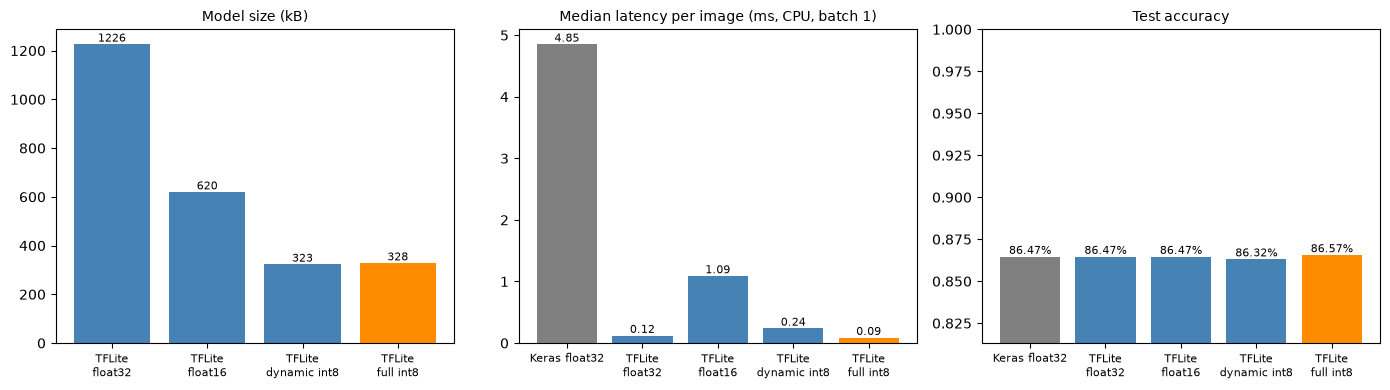

In [18]:
names = [r[0].replace("TFLite ", "TFLite\n") for r in rows]
colours = ["grey"] + ["steelblue"] * 3 + ["darkorange"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
panels = [(1, "Model size (kB)", "{:.0f}"), (2, "Median latency per image (ms, CPU, batch 1)", "{:.2f}"),
          (4, "Test accuracy", "{:.2%}")]
for ax, (k, label, fmt) in zip(axes, panels):
    idx = [i for i, r in enumerate(rows) if r[k] is not None]
    vals = [rows[i][k] for i in idx]
    bars = ax.bar([names[i] for i in idx], vals, color=[colours[i] for i in idx])
    ax.set_title(label, fontsize=10); ax.tick_params(axis="x", labelsize=8)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), fmt.format(v), ha="center", va="bottom", fontsize=8)
axes[2].set_ylim(min(r[4] for r in rows) - 0.05, 1)
plt.tight_layout(); plt.savefig(OUT_DIR / "optimisation_tradeoffs.png", dpi=150); plt.show()

## 10. Optimisation proposal: running the CNN without disturbing the robot
The table above gives the measured numbers. The proposal combines five ideas. Ideas 1–4 are **implemented** in the Webots controller, and idea 5 is future work.

1. **Run the CNN asynchronously, off the control loop.** The controller (`classifier.py`) runs inference on a background thread with a one-slot queue.
   `submit()` returns immediately, and if the CNN is still busy the older frame is dropped (*latest-frame-wins*). Motor commands and obstacle avoidance keep their 32 ms rhythm whatever the inference time is.
2. **Event-triggered inference with a cheap pre-filter.** HSV colour thresholding costs well under 1 ms per frame (the controller prints its measured average in every summary) and runs continuously.
   The expensive CNN only runs when something interesting happens: the robot reaches a block, the user presses **C**, or at start-up. That means a handful of inferences per minute instead of about 15 per second.
3. **Crop the region of interest.** The detector's bounding box gives a square crop around the object, which is then resized to 32×32. The CNN sees the object at the same framing as a CIFAR photo, and no time is spent on empty background.
4. **Quantise the model (post-training int8).** The table above shows the measured size reduction against float32 TFLite, the accuracy change, and how often int8 agrees with the float model.
   Whether int8 is also *faster* depends on the CPU: ARM chips like those in robots, and accelerators such as the Coral Edge TPU, have fast integer paths, while a laptop x86 CPU may not.
   The controller loads `cifar10_cnn_int8.tflite` first.
   The controller loads `cifar10_cnn_int8.tflite` first.
5. **Future work.**
   * *Pruning* (Han et al., 2016): remove low-magnitude weights, then fine-tune.
   * *Knowledge distillation* (Hinton et al., 2015): train a smaller student network from this one.
   * *Efficient architectures* such as MobileNet's depthwise-separable convolutions (Howard et al., 2017).
   * *Edge offloading*: send frames to a GPU server over Wi-Fi or ROS 2 when the robot's own CPU is too weak.
   * *Detection instead of classification*: fine-tune a small detector (for example SSD-MobileNet or YOLO) on Webots images of the blocks. It would give box positions and could add a "block" class that CIFAR-10 lacks.

## 11. Export the model for the robot
Copy `cifar10_cnn_int8.tflite` (and optionally `cifar10_cnn.keras`) into `webots_project/controllers/colour_detector/models/`.
The robot then needs either `pip install ai-edge-litert` (small) or the full `tensorflow` package in the Python that Webots uses.

In [19]:
import json, hashlib, shutil
card = {
    "model": "improved_cnn (CIFAR-10)", "classes": CLASS_NAMES,
    "input": "1x32x32x3 float32 RGB scaled to [0,1]; centre/ROI square crop, cv2 INTER_AREA resize",
    "output": "10 logits (apply softmax)", "seed": SEED, "split": "45k train / 5k val / 10k test",
    "val_accuracy": round(float(val_acc), 4), "test_accuracy": round(float(test_acc), 4),
    "tensorflow": tf.__version__, "quick_run": QUICK_RUN,
    "sha256": {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
               for p in sorted(OUT_DIR.glob("cifar10_cnn*")) if p.is_file()},
}
(OUT_DIR / "model_card.json").write_text(json.dumps(card, indent=2))
bundle = shutil.make_archive("cifar10_cnn_models", "zip", OUT_DIR)
print("Created", bundle, "with:", sorted(p.name for p in OUT_DIR.iterdir()))
if IN_COLAB:
    from google.colab import files
    files.download(bundle)

Created /private/tmp/claude-501/-Users-krishnamahajan-Library-Application-Support-Claude-scratch-workspaces-7a395be2-a6ae-420e-83f5-80271cad5f7c-dee63cf5-31ea-4364-82fe-af1e63d02abf-scratch-2026-11-11-8f8053/5e048983-eb6f-413f-a49a-79271b128064/scratchpad/cpurun/cifar10_cnn_models.zip with: ['cifar10_cnn.keras', 'cifar10_cnn.tflite', 'cifar10_cnn_dynamic.tflite', 'cifar10_cnn_fp16.tflite', 'cifar10_cnn_int8.tflite', 'confusion_matrix.png', 'model_card.json', 'optimisation_tradeoffs.png', 'training_curves.png']


## References
* Han, S., Mao, H. and Dally, W.J. (2016) 'Deep compression: compressing deep neural networks with pruning, trained quantization and Huffman coding', *ICLR*.
* Hinton, G., Vinyals, O. and Dean, J. (2015) 'Distilling the knowledge in a neural network', *arXiv:1503.02531*.
* Howard, A.G. *et al.* (2017) 'MobileNets: efficient convolutional neural networks for mobile vision applications', *arXiv:1704.04861*.
* Ioffe, S. and Szegedy, C. (2015) 'Batch normalization: accelerating deep network training by reducing internal covariate shift', *ICML*.
* Jacob, B. *et al.* (2018) 'Quantization and training of neural networks for efficient integer-arithmetic-only inference', *CVPR*.
* Kingma, D.P. and Ba, J. (2015) 'Adam: a method for stochastic optimization', *ICLR*.
* Krizhevsky, A. (2009) *Learning multiple layers of features from tiny images*. Technical report, University of Toronto.
* Lin, M., Chen, Q. and Yan, S. (2014) 'Network in network', *ICLR*.
* Simonyan, K. and Zisserman, A. (2015) 'Very deep convolutional networks for large-scale image recognition', *ICLR*.
* Srivastava, N. *et al.* (2014) 'Dropout: a simple way to prevent neural networks from overfitting', *JMLR*, 15, pp. 1929–1958.
* Cyberbotics (2025) *Webots R2025a reference manual*. Available at: https://cyberbotics.com/doc/reference/